##### Superhero Analysis 

- This `superhero_dataset.csv` was provided as part of a Data Analysis and Visualisation exercise
- This dataset contains key information about various superheroes, their origin,publisher and where they first appeared in an issue
- The below covers the key questions and hypothesis to be explore in this Jupyter notebook:

    1. Which publishers have introduced the most superheroes
        - This question examines which publishers have the highest count of superheroes in the dataset.
        - The current Hypothesis is it will be some of the the major publishers such as Marvel or DC.
    2. How are superheroes distributed across different origins?
        - (e.g., alien, human, mutant) across the entire dataset.
    3. Do major publishers focus on certain origins more than independent publishers?
        -  This question compares the origins of superheroes between major and independent publishers to determine if there is a significant difference in the types of origins they introduce.
    



In [252]:
print('Hello World')

Hello World


In [253]:
# import necessary libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

In [254]:
df = pd.read_csv('superhero_dataset.csv')
df

,first_appeared_in_issue,name,origin,publisher
0,The Legion of Super-Heroes,Lightning Lad,Alien,DC Comics
1,The Menace of Dream Girl!,Dream Girl,Alien,DC Comics
2,The War Between Supergirl and The Supermen Eme...,Brainiac 5,Alien,DC Comics
3,Hercules in the 20th Century!,Invisible Kid,Human,DC Comics
4,The War Between Supergirl and The Supermen Eme...,Phantom Girl,Alien,DC Comics
...,...,...,...,...
45219,The Future of Law Enforcement,Dick Jones,Human,Dynamite Entertainment
45220,The Future of Law Enforcement,Clarence Boddicker,Human,Dynamite Entertainment
45221,NaN,Dama Montalvo,Human,Dark Horse Comics
45222,"Blood,Sweat,& Fears",Lorca,Alien,Defiant


In [255]:
df.shape

(45224, 4)

In [256]:
df.isnull().sum()

first_appeared_in_issue    9243
name                          0
origin                        0
publisher                     0
dtype: int64

In [257]:
df.sample(20)

,first_appeared_in_issue,name,origin,publisher
21187,The Rainbow Creature,Jim Jansen,Human,DC Comics
16978,The Mighty Crusaders vs. The Brain Emperor,Eraser,Human,DC Comics
39231,NaN,Heidern,Human,SNK Playmore
3888,The Mountain!,Blowtorch,Human,IDW Publishing
25547,The Conquest of Superman,Brent Wood,Human,DC Comics
6747,The Red Star,Maya Antares,Human,Image
26860,terugkeer van Emplate,Murmur,Mutant,Marvel
4528,Be-Bop-A-Lisa; The End of El Barto,Kirk Van Houten,Human,Bongo
15106,Lex & Max; Sebastian’s Monster; Night Clubs Suck,Max,Human,SLG Publishing
19543,The Spook's Master Stroke!,Davy King,Human,DC Comics


In [258]:
df.describe()

,first_appeared_in_issue,name,origin,publisher
count,35981,45224,45224,45224
unique,17125,40342,10,580
top,Vol. 1,Angel,Human,Marvel
freq,245,11,27561,10921


In [259]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45224 entries, 0 to 45223
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   first_appeared_in_issue  35981 non-null  str  
 1   name                     45224 non-null  str  
 2   origin                   45224 non-null  str  
 3   publisher                45224 non-null  str  
dtypes: str(4)
memory usage: 1.4 MB


In [260]:
no_issue_mask = df['first_appeared_in_issue'].isnull()
no_issue_filter = df[no_issue_mask]
no_issue_filter

,first_appeared_in_issue,name,origin,publisher
17,NaN,Elysion,Human,DC Comics
18,NaN,Bodger,Human,DC Comics
19,NaN,Bonce,Human,DC Comics
20,NaN,Barney,Animal,Disney
21,NaN,Zepha,Alien,DC Comics
...,...,...,...,...
45171,NaN,Rick Jones,Human,Marvel
45173,NaN,Dr. Curtis Moss,Human,Marvel
45189,NaN,Grem,Alien,Archie Adventure Series
45214,NaN,Baby Face Finlayson,Human,D.C. Thomson & Co.


In [261]:
df=df[~no_issue_mask]
df.shape

(35981, 4)

In [262]:
df.isnull().sum()

first_appeared_in_issue    0
name                       0
origin                     0
publisher                  0
dtype: int64

In [263]:
unique_publishers_sorted = sorted(df['publisher'].unique())
unique_publishers_sorted

['12-Gauge Comics',
 '3ntini Editore',
 'A Wave Blue World',
 'AAA Pop',
 'AC Comics',
 'ADV Manga',
 'AK Comics',
 'ALL CAPS COMICS',
 'ASCII Media Works',
 'Aaaahh! Comics',
 'Aardvark',
 'Abrams ComicArts',
 'Abril',
 'Abstract Studio',
 'Acclaim',
 'Ace Comics',
 'Ace Magazines',
 'Ace Publications Inc',
 'Action Lab',
 'Active Images',
 'Aftershock Comics',
 'AiT/Planet Lar',
 'Aircel Publishing',
 'Airship Entertainment',
 'Ajax-Farrell',
 'Akita Shoten',
 'Albin Michel',
 'Alterna Comics',
 'Amalgam Comics',
 'Ambrosia Publishing',
 "America's Best Comics",
 'American Comics Group',
 'American Mythology Productions',
 'American Visuals Corporation',
 'Amerotica',
 'Amryl Entertainment',
 'Andrews McMeel Publishing',
 'Angry Viking Press',
 'Antarctic Press',
 'Antimatter',
 'Ape Entertainment',
 'Apex Comics Group',
 'Apparat',
 'Approbation Comics',
 'Arboris',
 'Arcana Studio',
 'Archaia',
 'Archie Adventure Series',
 'Archie Comics',
 'Armada',
 'Arnoldo Mondadori Editore',
 

In [264]:
df['name'].value_counts()

name
Doc                   8
Max                   8
Lucifer               8
Michael               8
Mirage                7
                     ..
Fray Tormenta         1
Dick Jones            1
Clarence Boddicker    1
Lorca                 1
Sueraceen             1
Name: count, Length: 32730, dtype: int64

In [265]:
unique_origins_sorted = sorted(df['origin'].unique())
unique_origins_sorted

['Alien',
 'Animal',
 'Cyborg',
 'God/Eternal',
 'Human',
 'Infection',
 'Mutant',
 'Other',
 'Radiation',
 'Robot']

In [266]:
df.head()

,first_appeared_in_issue,name,origin,publisher
0,The Legion of Super-Heroes,Lightning Lad,Alien,DC Comics
1,The Menace of Dream Girl!,Dream Girl,Alien,DC Comics
2,The War Between Supergirl and The Supermen Eme...,Brainiac 5,Alien,DC Comics
3,Hercules in the 20th Century!,Invisible Kid,Human,DC Comics
4,The War Between Supergirl and The Supermen Eme...,Phantom Girl,Alien,DC Comics


In [267]:
df['publisher'].unique().sum()

'DC ComicsMalibuNintendoAC ComicsFiction HouseHarry A. Chesler/DynamicFawcett PublicationsDisneyHolyokeMagazine EnterprisesTatsunoko ProductionZenescope EntertainmentNon-FictionalSNK PlaymoreTop CowRebellionMarvelValiantDark Horse ComicsWarp GraphicsAcclaimVertigoDynamite EntertainmentArchie ComicsChaos! ComicsWildstormCoffin ComicsImageBongoTopps ComicsEditoriale MercuryIDW PublishingEdiciones La Cúpula S.L.In the Public DomainSLG PublishingAntarctic PressKing Features SyndicateEclipseAmerican Mythology ProductionsCaliber ComicsEros ComixAntimatterHarveyChapterhouse ComicsECFurio Viano EditoreDevil\'s DueWhitmanDellGold KeyBoom! StudiosIcon ComicsFocusRed Eagle EntertainmentWarner BrothersShogakukanMattelAce MagazinesAmerica\'s Best ComicsEdiperiodiciVictor Gollancz Ltd.Abstract StudioDargaudHeroic PublishingCharltonSoleilSergio Bonelli EditoreCapcomEdizioni Star ComicsRaben & SjögrenDupuisModernJeunesse JoyeuseLe LombardHasbroFirstArmadaNew Worlds ComicsComicoVortex ComicsUnknown Pub

In [268]:
df['publisher'].value_counts().head(57)

publisher
Marvel                     10141
DC Comics                   8202
Vertigo                     2068
Dark Horse Comics           1358
Disney                      1003
IDW Publishing               895
In the Public Domain         849
Shueisha                     792
Image                        787
Wildstorm                    695
Non-Fictional                694
Rebellion                    485
Nintendo                     297
Top Cow                      290
Dynamite Entertainment       244
Kodansha                     241
Valiant                      215
Malibu                       207
Bongo                        175
Comico                       155
America's Best Comics        154
Amalgam Comics               152
Archie Comics                151
Dargaud                      128
Newspaper: Funny Pages       118
Warp Graphics                114
Boom! Studios                104
Hakusensha                   104
Square Enix                  104
Chaos! Comics                103


#### Any publisher with more than 100 comics would be classified as a major publisher

In [269]:
publisher_counts = df['publisher'].value_counts()
publisher_frequency = df['publisher'].map(publisher_counts)
publisher_frequency
df['publisher_category'] = 'independent'
df.loc[publisher_frequency >= 2500, 'publisher_category'] = 'major'
df['publisher_category'].value_counts()

publisher_category
major          18343
independent    17638
Name: count, dtype: int64

In [270]:
df.head()

,first_appeared_in_issue,name,origin,publisher,publisher_category
0,The Legion of Super-Heroes,Lightning Lad,Alien,DC Comics,major
1,The Menace of Dream Girl!,Dream Girl,Alien,DC Comics,major
2,The War Between Supergirl and The Supermen Eme...,Brainiac 5,Alien,DC Comics,major
3,Hercules in the 20th Century!,Invisible Kid,Human,DC Comics,major
4,The War Between Supergirl and The Supermen Eme...,Phantom Girl,Alien,DC Comics,major


In [271]:
origin_freq = df.groupby('origin')['origin'].value_counts().sort_values(ascending=False)
origin_freq

origin
Human          21711
Alien           3345
Other           2728
Animal          2133
Mutant          2064
God/Eternal     1989
Robot           1144
Cyborg           557
Radiation        181
Infection        129
Name: count, dtype: int64

Text(0.5, 1.0, 'Distribution of superhero origins')

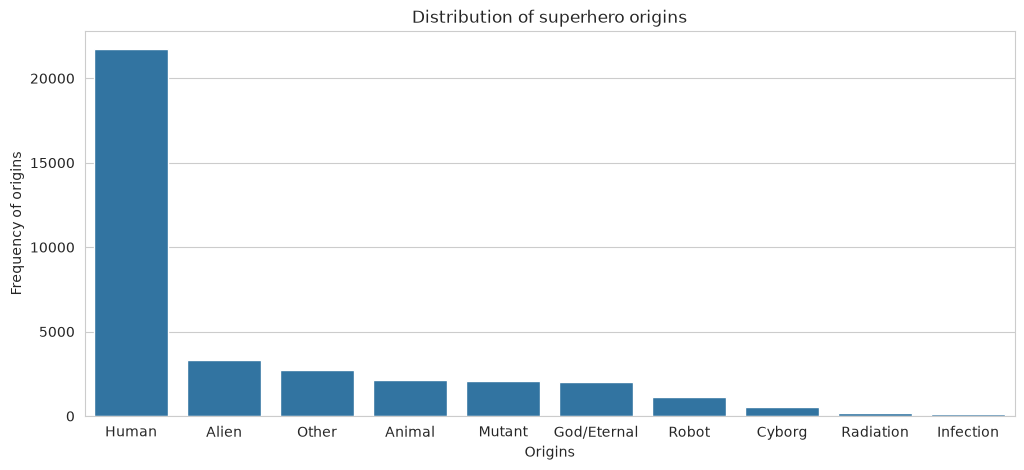

In [272]:
plt.figure(figsize=(12,5))
sns.barplot(x=origin_freq.index,y=origin_freq.values)
plt.xlabel('Origins')
plt.xticks(rotation=0)
plt.ylabel('Frequency of origins')
plt.title('Distribution of superhero origins')

In [273]:
publisher_frequency = df.groupby('publisher')['publisher'].value_counts().sort_values(ascending=False)
publisher_frequency
top_10_publishers = publisher_frequency.head(10)

Text(0.5, 1.0, 'Top 10 publishers based on comics released')

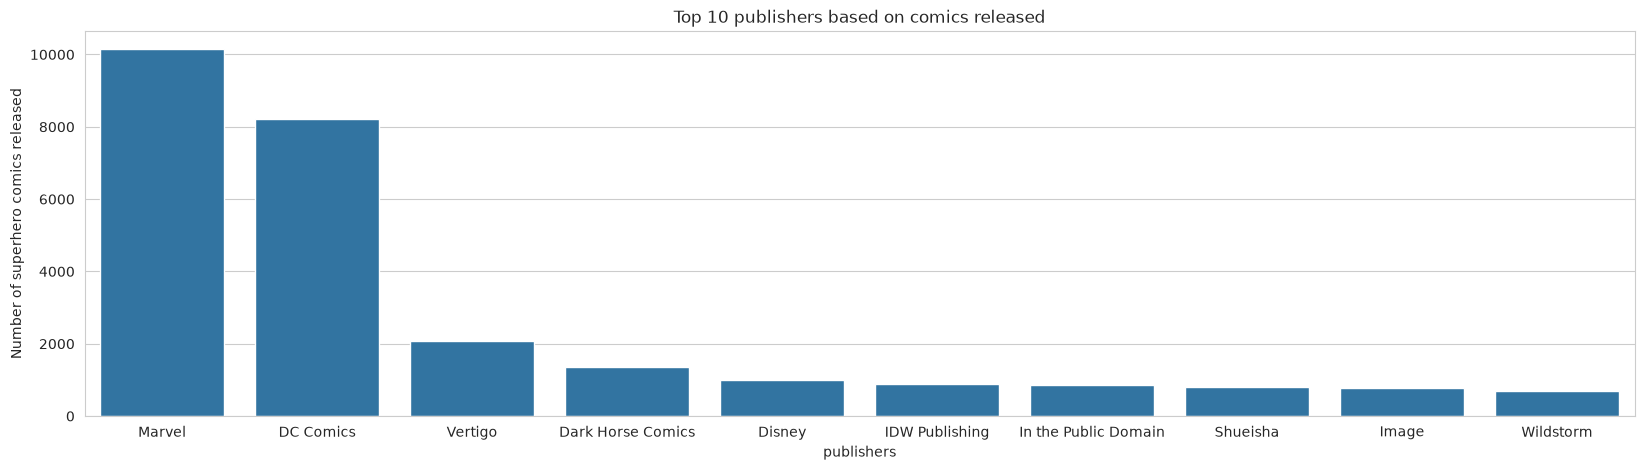

In [274]:
plt.figure(figsize=(20,5))
sns.barplot(x=top_10_publishers.index,y=top_10_publishers.values)
plt.xlabel('publishers')
plt.xticks(rotation=0)
plt.ylabel('Number of superhero comics released')
plt.title('Top 10 publishers based on comics released')

In [275]:
origin_publisher_category = pd.crosstab(
    df['origin'],
    df['publisher_category']
)
origin_publisher_category

publisher_category,independent,major
origin,,
Alien,1101,2244
Animal,1631,502
Cyborg,235,322
God/Eternal,1117,872
Human,10573,11138
Infection,82,47
Mutant,601,1463
Other,1487,1241
Radiation,45,136


Text(95.38563368055554, 0.5, 'Character Origin')

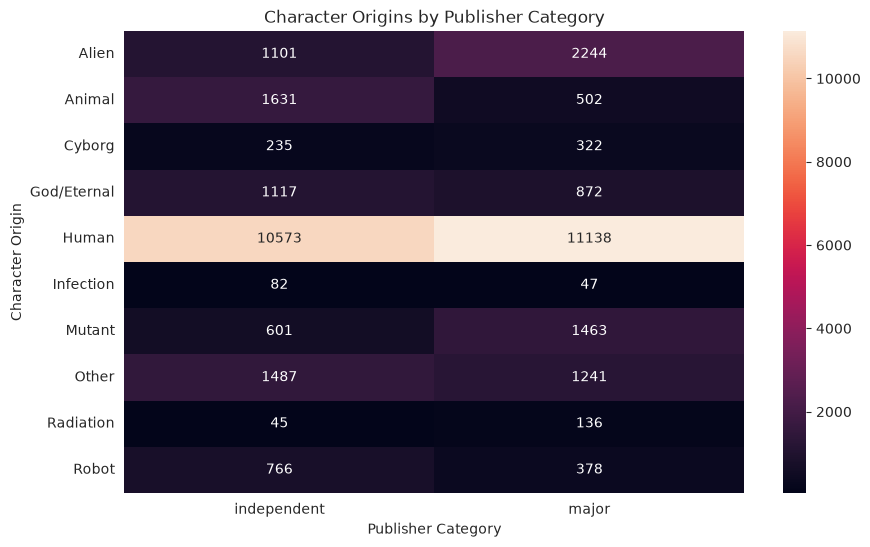

In [276]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    origin_publisher_category,
    annot=True,
    fmt='d'
    
)

plt.title('Character Origins by Publisher Category')
plt.xlabel('Publisher Category')
plt.ylabel('Character Origin')


## Key Findings

- The above analysis reveal the following findings
    1. Major publishers dominate majority of the superhero landscape with DC Comics and Marvel publishing more superheroes than the other 8 in the top 10 combined. Those 2 publishers up more than 18,000 of the 36,000 superheroes in this dataset.
    2. The distribution of the origins show that human superheroes are the most popular type of superheroes making up more than 21,700 of the 36,000 superheroes in the dataset.
    3. Testing whether major publishers focus more on certain origins than independent ones, the data shows that there is only a slight difference in the origin preferences across the types of publishers
        - Both publishjers have a heavy preference for human superheroes, with the independent having a greater focus in animal superheroes and major publishers having a greater focus in alien superheroes
    
## Future Analysis

- Future analysis could look at the popularity of the genre over time looking at publication dates as well as exploring how key superhero characteristics evolve over time.
- Additionaly, the popularity of certain superheroes can be analysed looking at whether they have been mande into a movies.
- All thi sanalysis would require more information in the dataset
